# Exercises for Section 3.5 Two-sample tests

This notebook contains the solutions to the exercises
from [Section 3.5 Two-sample tests]()
in the **No Bullshit Guide to Statistics**.

### Notebook setup

In [1]:
# Ensure required Python modules are installed
%pip install --quiet numpy scipy seaborn pandas ministats

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Figures setup
plt.clf()  # needed otherwise `sns.set_theme` doesn't work
sns.set_theme(
    context="paper",
    style="whitegrid",
    palette="colorblind",
    rc={"figure.figsize": (6, 1.6)},
)
%config InlineBackend.figure_format = "retina"

<Figure size 640x480 with 0 Axes>

In [4]:
# Simplified int and float __repr__
np.set_printoptions(legacy='1.25')

In [5]:
# Download datasets/ directory if necessary
from ministats import ensure_datasets
ensure_datasets()

datasets/ directory already exists.


$\def\stderr#1{\mathbf{se}_{#1}}$
$\def\stderrhat#1{\hat{\mathbf{se}}_{#1}}$
$\newcommand{\Mean}{\textbf{Mean}}$
$\newcommand{\Var}{\textbf{Var}}$
$\newcommand{\Std}{\textbf{Std}}$
$\newcommand{\Freq}{\textbf{Freq}}$
$\newcommand{\RelFreq}{\textbf{RelFreq}}$
$\newcommand{\DMeans}{\textbf{DMeans}}$
$\newcommand{\Prop}{\textbf{Prop}}$
$\newcommand{\DProps}{\textbf{DProps}}$
$$
\newcommand{\CI}[1]{\textbf{CI}_{#1}}
\newcommand{\CIL}[1]{\textbf{L}_{#1}}
\newcommand{\CIU}[1]{\textbf{U}_{#1}}
\newcommand{\ci}[1]{\textbf{ci}_{#1}}
\newcommand{\cil}[1]{\textbf{l}_{#1}}
\newcommand{\ciu}[1]{\textbf{u}_{#1}}
$$
(this cell contains the macro definitions like $\stderr{\overline{\mathbf{x}}}$, $\stderrhat{}$, $\Mean$, ...)

## Exercises

### E3.12

<!-- {exercise:samp-dist-dmeans-sleep-scores} -->

In an earlier exercise,
we calculated the difference between mean sleep scores
for doctors working in rural and urban locations: $\hat{d} = 7$.
In this exercise,
we want to describe the uncertainty in this estimate.

**a)** Obtain an approximation to the sampling distribution
of the difference between means
in terms of Student's $t$-distribution
centred at $\hat{d}$,
with scale $\stderrhat{\hat{d}}$,
and $\nu_d$ degrees of freedom.

**b)** Approximate the sampling distribution using the bootstrap.

**c)** Compare your answers from part **a)** and **b)** graphically.

In [59]:
# Load the doctors dataset and get the "rur" and "urb" scores
doctors = pd.read_csv("datasets/doctors.csv")
scoresR = doctors[doctors["loc"]=="rur"]["score"]
scoresU = doctors[doctors["loc"]=="urb"]["score"]

# observed value
dscores = scoresR.mean() - scoresU.mean()
dscores

6.992885375494076

In [60]:
# @studentprompt
# a) Analytical approximation

# Obtain the sample sizes and stds for the two groups
nR = ...
stdR = ...
nU = ...
stdU = ...

# Compute the standard error of the difference between means
seDhatscores = ...

# Calculate the degrees of freedom parameter
from ministats import calcdf
...

# Build a probability model based on Student's t-distribution
from scipy.stats import t as tdist
...

# Plot the PDF of the sampling distribution `rvDscores`
from ministats import plot_pdf
...

Ellipsis

Estimated standard error 3.5671565854251948


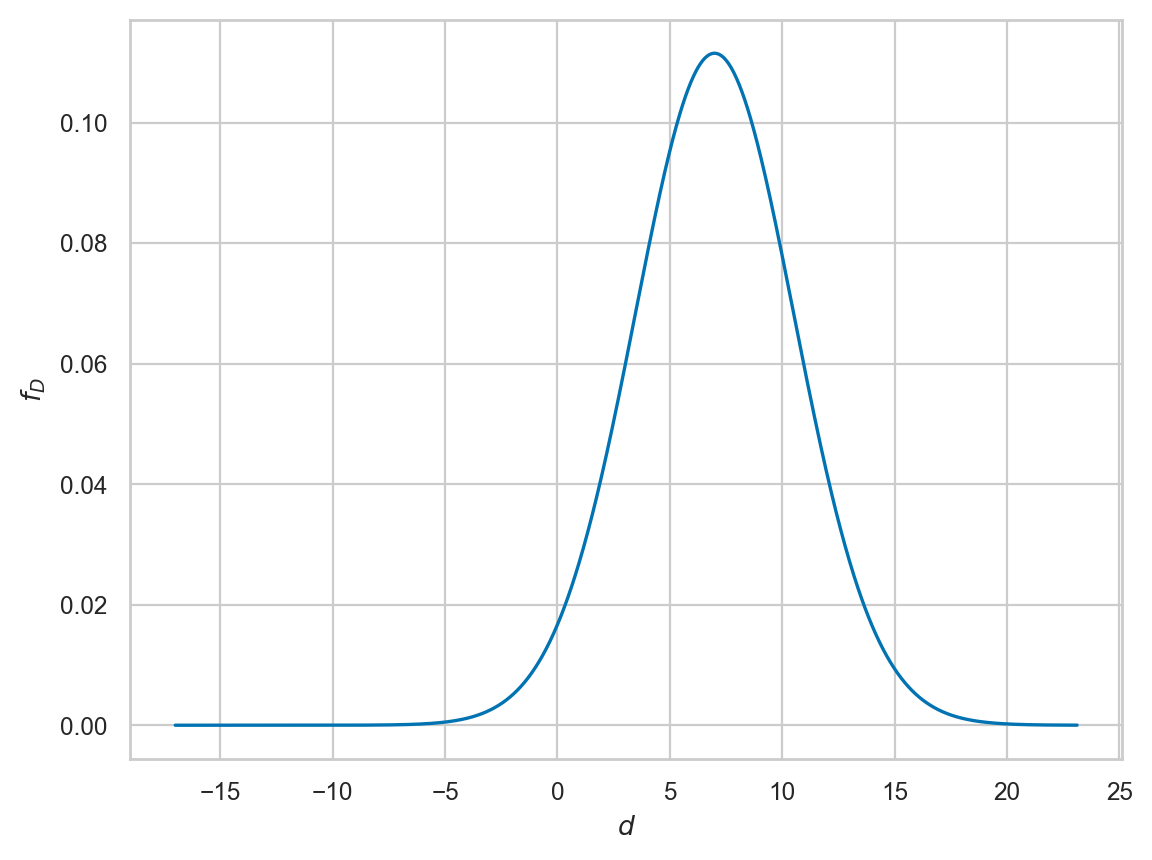

In [61]:
# @solution
# a) Analytical approximation

# Obtain the sample sizes and stds for the two groups
nR = len(scoresR)
stdR = scoresR.std()
nU = len(scoresU)
stdU = scoresU.std()

# Compute the standard error of the difference between means
seDhatscores = np.sqrt(stdU**2/nU + stdR**2/nR)
print("Estimated standard error", seDhatscores)

# Calculate the degrees of freedom parameter
from ministats import calcdf
df = calcdf(stdU, nU, stdR, nR)

# Build a probability model based on Student's t-distribution
from scipy.stats import t as tdist
rvDscores = tdist(df, loc=dscores, scale=seDhatscores)

# Plot the PDF of the sampling distribution `rvDscores`
from ministats import plot_pdf
plot_pdf(rvDscores, rv_name="D");

In [62]:
# @studentprompt
# b) Bootstrap estimate
# Set the random seed to a particular value to get a reproducible result
np.random.seed(51)

# Compute bootstrap estimates for mean in each group
from ministats import gen_boot_dist
meanR_boot = ... 
meanU_boot = ...

# Compute the difference between means of the bootstrap samples
dmeans_boot = ...

# Plot a histogram of the bootstrap distribution
...

Ellipsis

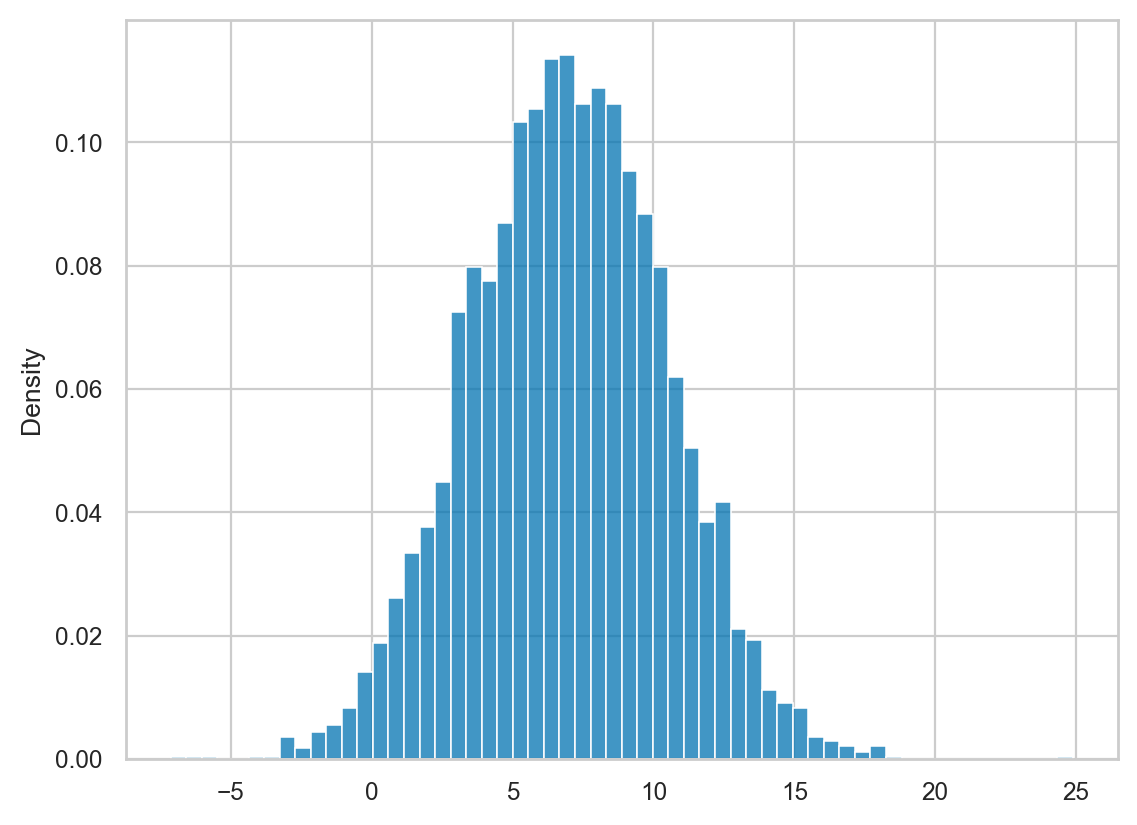

In [63]:
# @solution
# b) Bootstrap estimate
# Set the random seed to a particular value to get a reproducible result
np.random.seed(51)

# Compute bootstrap estimates for mean in each group
from ministats import gen_boot_dist
meanR_boot = gen_boot_dist(scoresR, estfunc=np.mean)
meanU_boot = gen_boot_dist(scoresU, estfunc=np.mean)

# Compute the difference between means of the bootstrap samples
dmeans_boot = np.subtract(meanR_boot, meanU_boot)

# Plot a histogram of the bootstrap distribution
sns.histplot(dmeans_boot, stat="density");

In [64]:
# @studentprompt
# c) Plot of the PDF of the analytical model
#    and the bootstrap distribution on the same axis
...

Ellipsis

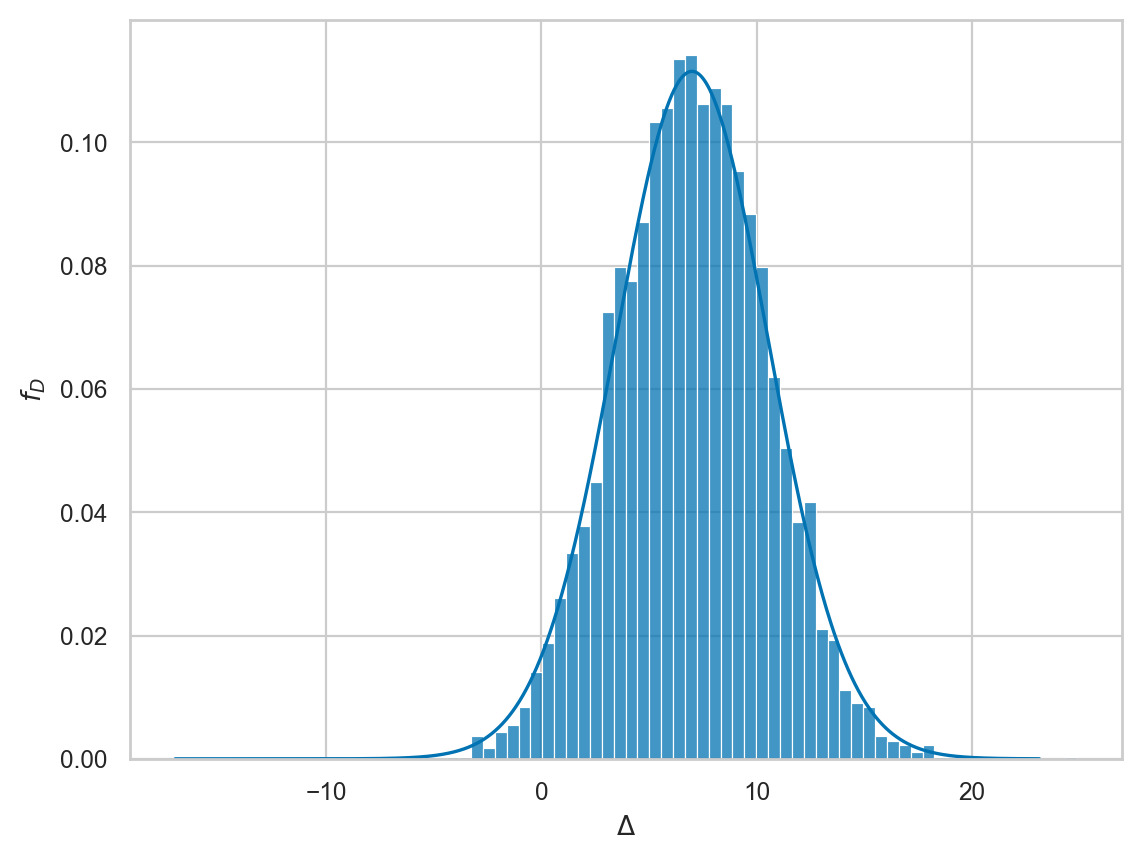

In [65]:
# @solution
# c) Plot of the PDF of the analytical model
#    and the bootstrap distribution on the same axis
ax = plot_pdf(rvDscores, rv_name="D")
sns.histplot(dmeans_boot, ax=ax, stat="density")
ax.set_xlabel(r"$\Delta$");

<!-- @solution -->
We see the two models for the uncertainty about $\Delta = \mu_R - \mu_U$ are very similar.

### E3.19

<!-- {exercise:ci95-dmeans-doctors-scores} -->

Construct a 95% confidence interval for the difference between mean scores
of doctors living in rural (`"rur"`) and urban (`"urb"`) locations
in the doctors dataset  
[`datasets/doctors.csv`](https://noBSstats.com/datasets/doctors.csv).

**a)** Use an analytical approximation based on Student's $t$-distribution.

**b)** Use the percentile bootstrap method.

In [17]:
# Define the `dmeans` estimator function
def dmeans(xsample, ysample):
    dhat = np.mean(xsample) - np.mean(ysample)
    return dhat

In [18]:
# Load the doctors dataset and get the "rur" and "urb" scores
doctors = pd.read_csv("datasets/doctors.csv")
scoresR = doctors[doctors["loc"]=="rur"]["score"]
scoresU = doctors[doctors["loc"]=="urb"]["score"]

# Calculate the difference between mean scores
dscores = dmeans(scoresR, scoresU)
dscores

6.992885375494076

#### a) Analytical approximation

In [19]:
# @studentprompt
# Obtain the sample sizes and stds of the two groups
nR = ...
stdR = ...
nU = ...
stdU = ...

# Calculate the standard error of the difference between means
...

# Calculate the degrees of freedom
from ministats import calcdf
dfD = ...

# Find the 0.025 and 0.975 quantiles of the standard t-dist.
from scipy.stats import t as tdist
...

# Construct a 95% CI for the difference between means
...

Ellipsis

In [20]:
# @solution
# Obtain the sample sizes and stds of the two groups
nR, stdR = len(scoresR), scoresR.std()
nU, stdU = len(scoresU), scoresU.std()

# Calculate the standard error of the difference between means
seDscores = np.sqrt(stdU**2/nU + stdR**2/nR)

# Calculate the degrees of freedom
from ministats import calcdf
dfD = calcdf(stdU, nU, stdR, nR)

# Find the 0.025 and 0.975 quantiles of the standard t-dist.
from scipy.stats import t as tdist
t_l = tdist(df=dfD).ppf(0.025)
t_u = tdist(df=dfD).ppf(0.975)

# Construct a 95% CI for the difference between means
[dscores + t_l*seDscores, dscores + t_u*seDscores]

[-0.10091806059740449, 14.086688811585557]

In [21]:
# @solution
# ALT. using t-distribution with custom `loc` and `scale` params
rvDscores = tdist(df=dfD, loc=dscores, scale=seDscores)
[rvDscores.ppf(0.025), rvDscores.ppf(0.975)]

[-0.10091806059740449, 14.086688811585557]

#### b) Bootstrap estimate

In [22]:
# @studentprompt
# Set the random seed to a particular value to get a reproducible result
np.random.seed(43)

# Compute bootstrap estimates for mean in each group
...

# Compute the difference between bootstrap means
dmeans_boot = ...

# Construct a 95% CI for the difference between means
...

Ellipsis

In [23]:
# @solution
# Set the random seed to a particular value to get a reproducible result
np.random.seed(43)

# Compute bootstrap estimates for mean in each group
meanR_boot = gen_boot_dist(scoresR, estfunc=np.mean)
meanU_boot = gen_boot_dist(scoresU, estfunc=np.mean)

# Compute the difference between bootstrap means
dmeans_boot = np.subtract(meanR_boot, meanU_boot)

# Construct a 95% CI for the difference between means
[np.quantile(dmeans_boot, 0.025), np.quantile(dmeans_boot, 0.975)]

[0.09320158102766672, 13.803270750988135]

### E3.20

<!-- {exercise:ci80-lecture-vs-debate-students-scores} -->

Construct an 80% confidence interval for the difference between means
of the debate (`"debate"`) and lecture (`"lecture"`) curriculum variants in the students dataset.

**a)** Use an analytical approximation based on Student's $t$-distribution.

**b)** Use the percentile bootstrap method.


In [24]:
# Load the students dataset and get the "debate" and "lecture" scores
students = pd.read_csv("datasets/students.csv")
scoresD = students[students["curriculum"]=="debate"]["score"]
scoresL = students[students["curriculum"]=="lecture"]["score"]

# Calculate the observed difference between mean scores
dhat = dmeans(scoresD, scoresL)
dhat

8.319642857142867

#### a) Analytical approximation

In [25]:
# @studentprompt
# Obtain the sample sizes and stds of the two groups
nD = ...
stdD = ...
nL = ...
stdL = ...

# Calculate the standard error of the difference between means
seDscores = ...

# Calculate the degrees of freedom
from ministats import calcdf
...

# Find the 0.1 and 0.9 quantiles of the standard t-dist.
from scipy.stats import t as tdist
...

# Construct an 80% CI for the difference between means
...

Ellipsis

In [26]:
# @solution
# Obtain the sample sizes and stds of the two groups
nD, stdD = len(scoresD), scoresD.std()
nL, stdL = len(scoresL), scoresL.std()

# Calculate the standard error of the difference between means
seDscores = np.sqrt(stdD**2/nD + stdL**2/nL)

# Calculate the degrees of freedom
from ministats import calcdf
dfD = calcdf(stdD, nD, stdL, nL)

# Find the 0.1 and 0.9 quantiles of the standard t-dist.
from scipy.stats import t as tdist
t_l = tdist(df=dfD).ppf(0.1)
t_u = tdist(df=dfD).ppf(0.9)

# Construct an 80% CI for the difference between means
[dhat + t_l*seDscores, dhat + t_u*seDscores]

[1.9164999884221352, 14.722785725863599]

#### b) Bootstrap estimate

In [27]:
# @studentprompt
# Set the random seed to a particular value to get a reproducible result
np.random.seed(42)

# Compute bootstrap estimates for mean in each group
...

# Compute the difference between bootstrap means
...

# Construct an 80% CI for the difference between means
...

Ellipsis

In [28]:
# @solution
# Set the random seed to a particular value to get a reproducible result
np.random.seed(42)

# Compute bootstrap estimates for mean in each group
meanD_boot = gen_boot_dist(scoresD, estfunc=np.mean)
meanL_boot = gen_boot_dist(scoresL, estfunc=np.mean)

# Compute the difference between bootstrap means
dmeans_boot = np.subtract(meanD_boot, meanL_boot)

# Construct an 80% CI for the difference between means
[np.percentile(dmeans_boot,10), np.percentile(dmeans_boot,90)]

[2.7105357142857174, 14.039464285714285]

### E3.38

<!-- {exercise:compare-rural-urban-doctors-permutation-test} -->

Use the permutation test to check for a difference between sleep scores
of doctors living in rural (`rur`) and urban (`urb`) locations
in the doctors dataset  
[`datasets/doctors.csv`](https://noBSstats.com/datasets/doctors.csv).

**a)** Formulate two competing hypotheses $H_0$ and $H_A$.

**b)** Calculate the observed difference between means $\hat{d}$.

**c)** Simulate $10\,000$ observations
from the distribution of the difference between means $\widehat{D}_0$
by calling `resample_under_H0`.

**d)** Compute the $p$-value of $\hat{d}$ (or a more extreme value) under $\widehat{D}_0$.

**e)** Make a decision if location affects sleep scores using $\alpha\!=\!0.05$.



In [6]:
# Load the doctors dataset and select the two groups
doctors = pd.read_csv("datasets/doctors.csv")
scoresU = doctors[doctors["loc"]=="urb"]["score"]
scoresR = doctors[doctors["loc"]=="rur"]["score"]

In [7]:
def dmeans(xsample, ysample):
    dhat = np.mean(xsample) - np.mean(ysample)
    return dhat

In [8]:
# @studentprompt
# b) Calculate the observed difference between means
dhat = ...

In [9]:
# @solution
# b) Calculate the observed difference between means
dhat = dmeans(scoresR, scoresU)
dhat

6.992885375494076

In [10]:
# @studentprompt
# Set the random seed to a particular value to get a reproducible result
np.random.seed(42)

# c) Simulate observations from the distribution of the difference between means under H0
from ministats.hypothesis_tests import resample_under_H0
P = 10000
pdhats0 = []
for j in range(0, P):
    ...

In [11]:
# @solution
# Set the random seed to a particular value to get a reproducible result
np.random.seed(42)

# c) Simulate observations from the distribution of the difference between means under H0
from ministats.hypothesis_tests import resample_under_H0
P = 10000
pdhats0 = []
for j in range(0, P):
    ps1, ps2 = resample_under_H0(scoresR, scoresU)
    pdhat0 = dmeans(ps1, ps2)
    pdhats0.append(pdhat0)

In [12]:
# @studentprompt
# d) Compute the $p$-value of `dhat` (or a more extreme value)
from ministats import tailvalues
tails = ...
pvalue = ...

In [13]:
# @solution
# d) Compute the p-value of `dhat` (or a more extreme value)
from ministats import tailvalues
tails = tailvalues(pdhats0, dhat, alt="two-sided")
pvalue = len(tails) / len(pdhats0)
pvalue

0.0527

In [14]:
# @solution
# Check the answer using `ministats.permutation_test_dmeans`
np.random.seed(42)
from ministats import permutation_test_dmeans
permutation_test_dmeans(scoresR, scoresU, P=10000)

0.0527

In [15]:
# @solution
# Check the answer using `scipy.stats.permutation_test`
np.random.seed(42)
from scipy.stats import permutation_test
permutation_test([scoresR,scoresU], dmeans, n_resamples=10000).pvalue

0.05399460053994601

<!-- @solution -->
**e)** 
The $p$-value is above $\alpha=0.05$ so we have failed to reject $H_0$.

### E3.39

<!-- {exercise:compare-treat-ctrl-iqs2-permutation-test} -->

Apply the permutation test to compare the `treat` and `ctrl` groups in the IQ scores dataset 
[`datasets/iqs2.csv`](https://noBSstats.com/datasets/iqs2.csv).

In [16]:
# Load the dataset and select the two groups
iqs2 = pd.read_csv("datasets/iqs2.csv")
treated = iqs2[iqs2["group"]=="treat"]["iq"]
controls = iqs2[iqs2["group"]=="ctrl"]["iq"]

In [17]:
# @studentprompt
# Calculate the observed difference between means
dhat_iqs = dmeans(treated, controls)
dhat_iqs

1.5577507598784166

In [18]:
# @solution
# Calculate the observed difference between means
dhat_iqs = dmeans(treated, controls)
dhat_iqs

1.5577507598784166

In [19]:
# @studentprompt
# Set the random seed to a particular value to get a reproducible result
np.random.seed(43)

# Obtain the sampling distribution of the difference between means under H0
from ministats.hypothesis_tests import resample_under_H0
pdhats0 = ...

# Compute the p-value of `dhat` (or a more extreme value)
from ministats import tailvalues
tails = ...
pvalue = ...

In [20]:
# @solution
# Set the random seed to a particular value to get a reproducible result
np.random.seed(43)

# Obtain the sampling distribution of the difference between means under H0
from ministats.hypothesis_tests import resample_under_H0
P = 10000
pdhats0 = []
for j in range(0, P):
    ps1, ps2 = resample_under_H0(treated, controls)
    pdhat0 = dmeans(ps1, ps2)
    pdhats0.append(pdhat0)

# Compute the p-value of `dhat` (or a more extreme value)
from ministats import tailvalues
tails = tailvalues(pdhats0, dhat_iqs, alt="two-sided")
pvalue = len(tails) / len(pdhats0)
pvalue

0.1283

In [21]:
# @solution
# Check the answer using `ministats.permutation_test_dmeans`
np.random.seed(43)
from ministats import permutation_test_dmeans
permutation_test_dmeans(treated, controls)

0.1283

### E3.40

<!-- {exercise:compare-rural-urban-doctors-t-test} -->

Compare the sleep scores for `rur`al and `urb`an in the doctors dataset
([`datasets/doctors.csv`](https://noBSstats.com/datasets/doctors.csv)).
Use Welch's two-sample $t$-test based on the two-sided alternative hypothesis.

**a)** Formulate two competing hypotheses $H_0$ and $H_A$.

**b)** Calculate the difference between means
$\hat{d} = \mathbf{dmeans}(\mathbf{x}_R,\mathbf{x}_U)$
and the sample standard deviations $s_{\mathbf{x}_R}$ and $s_{\mathbf{x}_U}$.

**c)** Compute the estimated standard error of the sampling distribution
$\stderr{\hat{d}}$ and the degrees of freedom parameter $\nu_d$.

**d)** Calculate the $t$-statistic.

**e)** Compute the $p$-value of the $t$-statistic under $T_0 \sim \mathcal{T}(\nu_d)$.

**f)** Check your answer using the `ministats` function `ttest_dmeans`.

**g)** Check your answer using the `scipy.stats` function `ttest_ind`.

In [22]:
# Load the doctors dataset and select the two groups
doctors = pd.read_csv("datasets/doctors.csv")
scoresU = doctors[doctors["loc"]=="urb"]["score"]
scoresR = doctors[doctors["loc"]=="rur"]["score"]

<!-- @solution -->
**a)**
The two competing hypotheses are

$$
 H_A: \mu_R\!\neq\!\mu_U
 \qquad \text{and} \qquad
 H_0: \mu_R\!=\!\mu_U,
$$
where $\mu_R$ is the mean sleep score for doctors living in rural locations,
and $\mu_U$ is the mean for doctors living in urban locations.

In [23]:
# @studentprompt
# b) Calculate the observed difference between means ...
dhat = ...

# ... the sample sizes ...
nR = ...
nU = ...

# ... and the standard deviations
stdR = ...
stdU = ...

In [24]:
# @solution
# b) Calculate the observed difference between means ...
dhat = dmeans(scoresR, scoresU)
print("dhat =", dhat)

# ... the sample sizes ...
nR, nU = len(scoresR), len(scoresU)
print("sample sizes", nR, nU)

# ... and the standard deviations
stdR, stdU = scoresR.std(), scoresU.std()
stdR, stdU

dhat = 6.992885375494076
sample sizes 46 110


(20.355677910313027, 20.22031282833502)

In [25]:
# @studentprompt
# c) Compute the standard error of the estimator D
seD = ...

# ... and the degrees of freedom
from ministats import calcdf
...

Ellipsis

In [26]:
# @solution
# c) Compute the estimated standard error ...
seD = np.sqrt(stdR**2/nR + stdU**2/nU)
print("seD =", seD)

# ... and the degrees of freedom
from ministats import calcdf
dfD = calcdf(stdR, nR, stdU, nU)
dfD

seD = 3.5671565854251948


83.90175080782984

In [27]:
# @studentprompt
# d) Compute the value of the t-statistic
obst = ...

In [28]:
# @solution
# d) Compute the value of the t-statistic
obst = (dhat - 0) / seD
obst

1.9603527930525495

In [29]:
# @studentprompt
# e) Calculate the p-value
from scipy.stats import t as tdist
rvT0 = ...
from ministats import tailprobs
pvalue = ...

In [30]:
# @solution
# e) Calculate the p-value
from scipy.stats import t as tdist
rvT0 = tdist(df=dfD)
from ministats import tailprobs
pvalue = tailprobs(rvT0, obst, alt="two-sided")
pvalue

0.05327318474001391

In [31]:
# @studentprompt
# f) Check your answer using the `ministats` function `ttest_dmeans`
from ministats import ttest_dmeans
...

Ellipsis

In [32]:
# @solution
# f) Check your answer using the `ministats` function `ttest_dmeans`
from ministats import ttest_dmeans
ttest_dmeans(scoresR, scoresU)

0.05327318474001391

In [33]:
# @studentprompt
# g) Check your answer using the `scipy.stats` function `ttest_ind`
from scipy.stats import ttest_ind
...

Ellipsis

In [34]:
# @solution
# g) Check your answer using the `scipy.stats` function `ttest_ind`
from scipy.stats import ttest_ind
ttest_ind(scoresR, scoresU, equal_var=False)

TtestResult(statistic=1.9603527930525495, pvalue=0.05327318474001396, df=83.90175080782984)

### E3.41

<!-- {exercise:compare-treat-ctrl-iqs2-t-test} -->

Apply Welch's two-sample $t$-test
to compare the `treat` and `ctrl` groups in the IQ scores dataset
[`datasets/iqs2.csv`](https://noBSstats.com/datasets/iqs2.csv).


In [35]:
# Load the dataset and select the two groups
iqs2 = pd.read_csv("datasets/iqs2.csv")
treated = iqs2[iqs2["group"]=="treat"]["iq"]
controls = iqs2[iqs2["group"]=="ctrl"]["iq"]

In [36]:
# @studentprompt
# Calculate the observed difference between means
...

Ellipsis

In [37]:
# @solution
# Calculate the observed difference between means
dhat_iqs = dmeans(treated, controls)
dhat_iqs

1.5577507598784166

In [38]:
# @solution
# Compute sample sizes and the standard deviations
nT, nC = len(treated), len(controls)
stdT, stdC = treated.std(), controls.std()

# Compute the estimated standard error
seD = np.sqrt(stdT**2/nT + stdC**2/nC)
print("seD =", seD)

# ... and the degrees of freedom
from ministats import calcdf
dfD = calcdf(stdT, nT, stdC, nC)
dfD

seD = 0.9602761210175937


63.03889717357651

In [39]:
# @solution
# Compute the value of the t-statistic
obst = (dhat_iqs - 0) / seD
obst

1.622190457290228

In [40]:
# @solution
# Calculate the p-value
from scipy.stats import t as tdist
rvT0p = tdist(df=dfD)
from ministats import tailprobs
pvalue = tailprobs(rvT0p, obst, alt="two-sided")
pvalue

0.10975381983712837

In [41]:
# @solution
# Check answer using the `ministats` function `ttest_dmeans`
from ministats import ttest_dmeans
ttest_dmeans(treated, controls, equal_var=False)

0.10975381983712842

In [42]:
# @solution
# Check answer using the `scipy.stats` function `ttest_ind`
from scipy.stats import ttest_ind
ttest_ind(treated, controls, equal_var=False)

TtestResult(statistic=1.622190457290228, pvalue=0.10975381983712833, df=63.03889717357651)

### E3.42

<!-- exercise:student-scores-with-pooled-variance} -->

In Example 2T,
we applied Welch's $t$-test to Charlotte's students dataset
[`datasets/students.csv`](https://noBSstats.com/datasets/students.csv).
Repeat the analysis of this dataset using Student's two-sample $t$-test with pooled variance.


Hint: Perform the calculations from scratch then check your answer using `scipy.stats.ttest_ind` used with the option `equal_var=True`.



In [43]:
# Load the students dataset and select the two groups
students = pd.read_csv("datasets/students.csv")
scoresD = students[students["curriculum"]=="debate"]["score"]
scoresL = students[students["curriculum"]=="lecture"]["score"]

In [44]:
# @studentprompt


In [45]:
# @solution
# Calculate the observed difference between means
dscore = dmeans(scoresD, scoresL)
dscore

8.319642857142867

In [46]:
# @solution
# Compute sample sizes and the standard deviations
nD, nL = len(scoresD), len(scoresL)
stdD, stdL = scoresD.std(), scoresL.std()

# Compute the pooled variance and standard error of estimator D
varp = ((nD-1)*stdD**2 + (nL-1)*stdL**2) / (nD + nL - 2)
stdp = np.sqrt(varp)
seDp = stdp * np.sqrt(1/nD + 1/nL)
seDp

4.837601461703548

In [47]:
# @solution
# Compute the value of the t-statistic
obstp = (dscore - 0) / seDp
obstp

1.7197867420465696

In [48]:
# @solution
# Obtain the degrees of freedom
dfDp = nD + nL - 2
dfDp

13

In [49]:
# @solution
# Calculate the p-value
from scipy.stats import t as tdist
rvT0p = tdist(df=dfDp)
from ministats import tailprobs
pvaluep = tailprobs(rvT0p, obstp, alt="two-sided")
pvaluep

0.1091723444321433

In [50]:
# @solution
# Check answer using the `ministats` function `ttest_dmeans`
from ministats import ttest_dmeans
ttest_dmeans(scoresD, scoresL, equal_var=True)

0.1091723444321433

In [51]:
# @solution
# Check answer using the `scipy.stats` function `ttest_ind`
from scipy.stats import ttest_ind
ttest_ind(scoresD, scoresL, equal_var=True)

TtestResult(statistic=1.7197867420465698, pvalue=0.10917234443214319, df=13.0)

### E3.43

<!-- {exercise:compare-West-and-East-beer-prices} -->

Your friend Ben,
who totally doesn't have a drinking problem,
decided to scientifically compare the price of a pint of beer in the West End and the East End of the city.
He sent you the following summary statistics for the prices in the West:
$\overline{\mathbf{x}}_W=10$, $s_{\mathbf{x}_W}=1$, and $n_W=7$.
The corresponding stats from the East are
$\overline{\mathbf{x}}_E=8$, $s_{\mathbf{x}_E}=1.5$, and $n_E=6$.
Run Welch's two-sample $t$-test on this data to detemine
if there is a difference between the West and East prices.

In [52]:
# Sample statistics from the problem statement
meanW, stdW, nW = 10, 1, 7
meanE, stdE, nE = 8, 1.5, 6

In [53]:
# @studentprompt
# Compute the difference between means
dhat_beer = ...

# Compute the estimated standard error
seD = ...

# ... and the degrees of freedom
from ministats import calcdf
dfD = ...

# Compute the value of the t-statistic
obst = ...

# Calculate the p-value
from scipy.stats import t as tdist
rvT0 = ...
from ministats import tailprobs
pvalue = ...

In [54]:
# @solution
# Compute the difference between means
dhat_beer = meanW - meanE

# Compute the estimated standard error
seD = np.sqrt(stdW**2/nW + stdE**2/nE)
print("seD =", seD)

# ... and the degrees of freedom
from ministats import calcdf
dfD = calcdf(stdW, nW, stdE, nE)
dfD

seD = 0.7196229171289243


8.506405933917732

In [55]:
# @solution
# Compute the value of the t-statistic
obst = (dhat_beer - 0) / seD
obst

2.779233335118605

In [56]:
# @solution
# Calculate the p-value
from scipy.stats import t as tdist
rvT0 = tdist(df=dfD)
from ministats import tailprobs
pvalue = tailprobs(rvT0, obst, alt="two-sided")
pvalue

0.022588387283169822

In [57]:
# @studentprompt
from scipy.stats import ttest_ind_from_stats
...

Ellipsis

In [58]:
# @solution
from scipy.stats import ttest_ind_from_stats
ttest_ind_from_stats(mean1=meanW, std1=stdW, nobs1=nW,
                     mean2=meanE, std2=stdE, nobs2=nE,
                     equal_var=False)

Ttest_indResult(statistic=2.779233335118605, pvalue=0.02258838728316984)